In [174]:
import pandas as pd
df=pd.read_csv(r"C:\Users\dell\Downloads\transactions_TP2.csv")
print(df.head())

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [175]:
print(df.shape)

(3045, 12)


In [176]:
print(df.dtypes)

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


In [177]:
manquant=df.isna().sum()
print(manquant)

id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude                0
dtype: int64


In [178]:
pourcentage=df.isna().mean()*100
print(pourcentage)

id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64


In [179]:

T= pd.DataFrame({'manquant': manquant , 'pourcentage': pourcentage})
T=T.sort_values('pourcentage',ascending=False)
print(T)


                  manquant  pourcentage
canal                  159     5.221675
anciennete_mois        137     4.499179
appareil               122     4.006568
montant_dh             110     3.612479
region                 103     3.382594
nb_ops_24h              53     1.740558
id_operation             0     0.000000
id_client                0     0.000000
heure                    0     0.000000
international            0     0.000000
resultat_enquete         0     0.000000
fraude                   0     0.000000


In [180]:
print("nombres de doublons est:",df["id_operation"].duplicated().sum())

nombres de doublons est: 45


In [181]:
nbr_doub=df["id_operation"].duplicated().sum()
df=df.drop_duplicates(subset="id_operation")
print("le nombre de lignes restantes:",len(df))

le nombre de lignes restantes: 3000


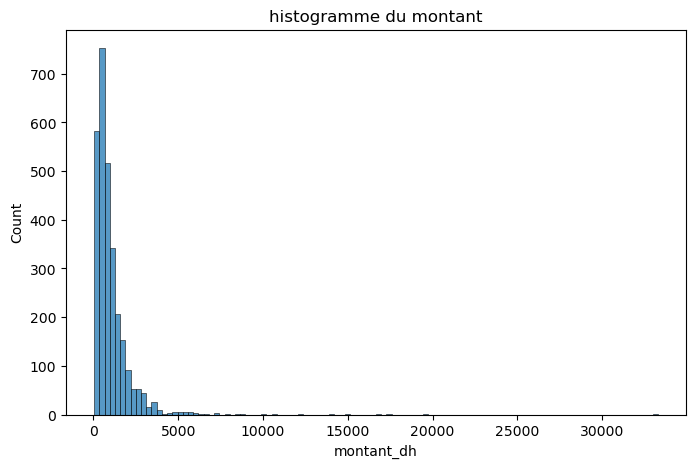

In [182]:
import  matplotlib.pyplot as plt 
import seaborn as sns
plt.figure(figsize=(8,5))
sns.histplot(df["montant_dh"])
plt.title("histogramme du montant")
plt.show()

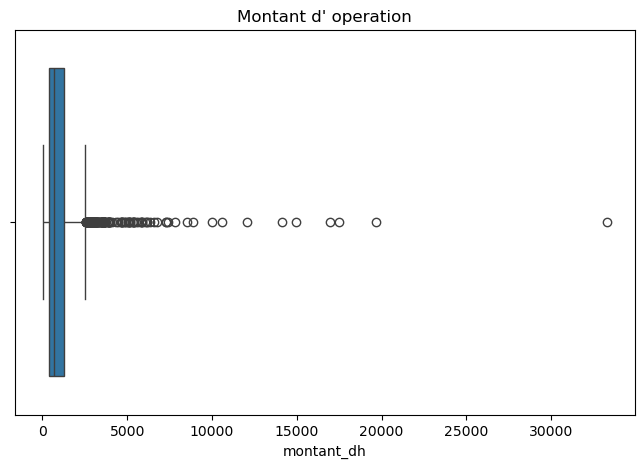

In [183]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["montant_dh"])
plt.title("Montant d' operation")
plt.show()

In [184]:
print(df["fraude"].value_counts())
print( "la proportion:",df["fraude"].value_counts(normalize=True)*100)

fraude
0    2742
1     258
Name: count, dtype: int64
la proportion: fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


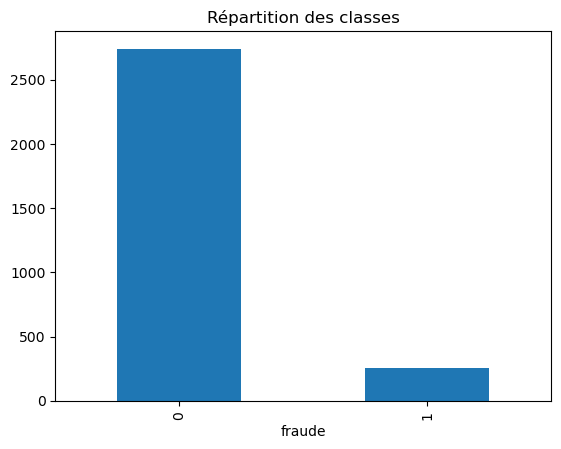

In [185]:
df['fraude'].value_counts().plot(kind='bar')
plt.title("Répartition des classes")
plt.show()

Partie2:Préparer les données sans fuite


In [186]:

Y=df["fraude"]
X=df.drop(columns=["fraude","id_operation","id_client","resultat_enquete"])


In [187]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20,stratify=Y,random_state=42)
cols_numr=X.select_dtypes(include=["int64","float64"]).columns
cols_catego=X.select_dtypes(include=["object"]).columns
print ("les colonnes numerique sont:",list(cols_numr))
print("les colonnes calégorie sont:",list(cols_catego))

les colonnes numerique sont: ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
les colonnes calégorie sont: ['canal', 'appareil', 'region', 'international']


In [226]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
num_pepline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
     ("scaler",StandardScaler())
 ])
 


In [189]:
from sklearn.preprocessing import OneHotEncoder
cat_pipeline=Pipeline([
('imputer',SimpleImputer(strategy='most_frequent')),
('onehot',OneHotEncoder(handle_unknown="ignore"))
])

In [190]:
from sklearn.compose import ColumnTransformer
prep=ColumnTransformer(
    transformers=[
        ("categorie",cat_pipeline,cols_catego),
        ("numeric", num_pepline,cols_numr)
    ])


In [191]:
x_train_n=prep.fit_transform(x_train)
x_test_n=prep.transform(x_test)
print(x_train_n.shape)
print(x_test_n.shape)

(2400, 18)
(600, 18)


In [192]:
from sklearn.preprocessing import RobustScaler
Robust_pipline=Pipeline([("imputer",SimpleImputer(strategy='median')),
("scaler",RobustScaler())])
x_train_r=Robust_pipline.fit_transform(x_train[cols_numr])
x_test_r=Robust_pipline.transform(x_test[cols_numr])


q1=x_train["montant_dh"].quantile(0.25)
q3=x_train["montant_dh"].quantile(0.75)
IQR=q3-q1

print("Q1=",q1)
print("Q3=",q3)
print("IQR=",IQR)

Q1= 393.095
Q3= 1249.8775
IQR= 856.7825


In [193]:
L=q1-1.5*IQR
U=q3+1.5*IQR
med_remp=x_train["montant_dh"].median()
x_m=x_train[(x_train["montant_dh"]<L )|( x_train["montant_dh"]>U)]
print("median est",med_remp)
print("L=",L)
print("U=",U)
print(len(x_m))


median est 710.79
L= -892.0787499999999
U= 2535.05125
146


Text(0.5, 1.0, 'conserver les montants extrêmes')

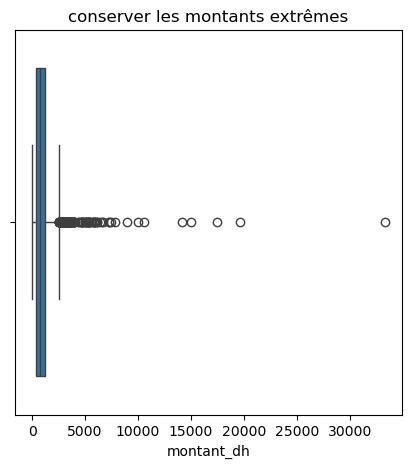

In [194]:
x_train_cl=x_train.copy()
x_train_cl['montant_dh']=x_train_cl['montant_dh'].clip(lower=L,upper=U)
plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.boxplot(x=x_train['montant_dh'])
plt.title ("conserver les montants extrêmes")

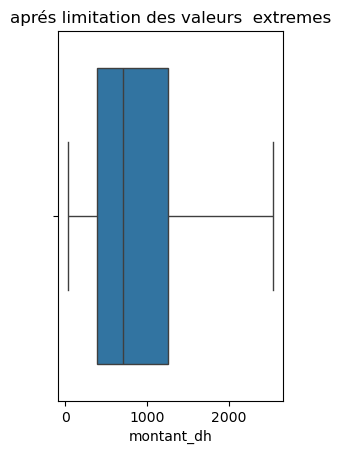

In [195]:
plt.subplot(1,2,1)
sns.boxplot(x=x_train_cl["montant_dh"])
plt.title("aprés limitation des valeurs  extremes")
plt.show()

In [196]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
scaleer={}
Result_train={}
for n,scaler in[
 ('scaler_mM',MinMaxScaler()),('scaler_std',StandardScaler()),('scaler_robu',RobustScaler())]:
    x_train_sca=scaler.fit_transform(x_train[['montant_dh']])
    x_test_sca=scaler.transform(x_test[['montant_dh']])
    Result_train[n]=scaler.transform(x_train[['montant_dh']])
    scaleer[n]=scaler

In [197]:
montant_test=pd.DataFrame({'montant_dh':[100,150,600,33281.230]})
tableau=pd.DataFrame({
    'Monatant':montant_test['montant_dh'],
    'MinMaxScaler':scaleer['scaler_mM'].transform(montant_test).ravel(),
    'StandardScaler':scaleer['scaler_std'].transform(montant_test).ravel(),
    'RobustScaler':scaleer['scaler_robu'].transform(montant_test).ravel()
})
print(tableau)

   Monatant  MinMaxScaler  StandardScaler  RobustScaler
0    100.00      0.001913       -0.690077     -0.712888
1    150.00      0.003417       -0.653074     -0.654530
2    600.00      0.016953       -0.320050     -0.129309
3  33281.23      1.000000       23.865830     38.014829


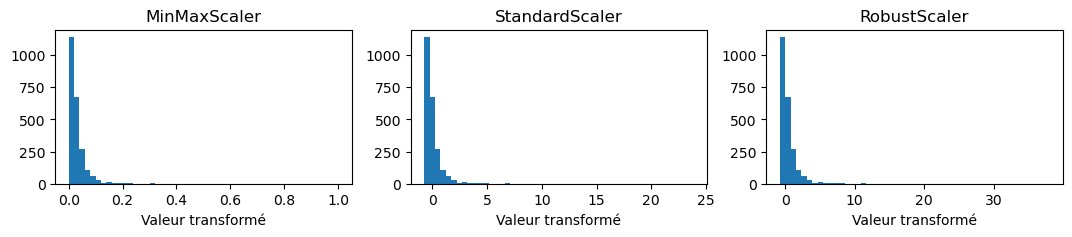

In [198]:
import matplotlib.pyplot as plt
plt.figure(figsize=(13,2))
#histogramme MnMaxScaler
plt.subplot(1,3,1)
plt.hist(Result_train['scaler_mM'],bins=50)
plt.title("MinMaxScaler")
plt.xlabel("Valeur transformé")

#histogramme standarisation
plt.subplot(1,3,2)
plt.hist(Result_train['scaler_std'],bins=50)
plt.title("StandardScaler")
plt.xlabel("Valeur transformé")
#histogramme de RobustScaler
plt.subplot(1,3,3)
plt.hist(Result_train['scaler_robu'],bins=50)
plt.title("RobustScaler")
plt.xlabel("Valeur transformé")

plt.show()

In [199]:
print(y_train.value_counts())
print( "la proportion:",y_train.value_counts(normalize=True)*100)

fraude
0    2194
1     206
Name: count, dtype: int64
la proportion: fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64


In [200]:
from imblearn.over_sampling import RandomOverSampler
Over=RandomOverSampler(random_state=True)
x_Over,y_Over=Over.fit_resample(x_train,y_train)
print(y_train.value_counts(),y_Over.value_counts())

fraude
0    2194
1     206
Name: count, dtype: int64 fraude
0    2194
1    2194
Name: count, dtype: int64


In [201]:
from imblearn.under_sampling import RandomUnderSampler

under=RandomUnderSampler(random_state=True)
x_un,y_un=under.fit_resample(x_train,y_train)
print(y_train.value_counts(),y_un.value_counts())

fraude
0    2194
1     206
Name: count, dtype: int64 fraude
0    206
1    206
Name: count, dtype: int64


In [220]:
import numpy as np
X=[16,20]
Y=[20,60]
coef=0.6
syst=[]
for i in range (len(X)):
 valr_synt=X[i]+coef*(Y[i]-X[i])
 syst.append(valr_synt)
print( "valeur synthétique :",syst)

valeur synthétique : [18.4, 44.0]


In [202]:
Tableau_compa=pd.DataFrame({
    'Avant':y_train.value_counts(),
    'Aprés(OverSampling)':y_Over.value_counts(),
    'Aprés(Undersampling)':y_un.value_counts()
})
print(" tableau les effectifs des classes ")
print(Tableau_compa)

 tableau les effectifs des classes 
        Avant  Aprés(OverSampling)  Aprés(Undersampling)
fraude                                                  
0        2194                 2194                   206
1         206                 2194                   206


In [203]:
num_pepline_end=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
     ("scaler",RobustScaler())
 ])
cat_pepline_end=Pipeline([
('imputer',SimpleImputer(strategy='most_frequent')),
('encode',OneHotEncoder(handle_unknown="ignore"))
])
prepro_final=ColumnTransformer([
     ("numer",num_pepline_end,cols_numr),
     ("catego",cat_pepline_end,cols_catego)
 ])

In [204]:
x_train_end=prepro_final.fit_transform(x_train)
x_test_end=prepro_final.transform(x_test)

print(x_train_end.shape)
print(x_test_end.shape)

(2400, 18)
(600, 18)


In [205]:
import numpy as np
print(np.isnan(x_train_end).sum())
print(np.isnan(x_test_end).sum())

0
0


In [206]:
import matplotlib.pyplot as plt
import pandas as pd 
from sklearn.impute import SimpleImputer
imputer_moy=SimpleImputer(strategy='mean')
imputer_me=SimpleImputer(strategy='median')

In [224]:
import numpy as np
Montant=np.array([ 100, 120, 180, 150, 1000])
Moyenne=np.mean(Montant)
Median=np.median(Montant)
print ("la moyenne est:",Moyenne)
print ("la median est:",Median)

la moyenne est: 310.0
la median est: 150.0
